
# Step 1: Data Loading and Preparation
1.1. Assign Column Names and Load Data




In [2]:
import pandas as pd

# Define column names based on MODIS documentation
columns = [
    'latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time',
    'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp',
    'daynight', 'type'
]

# Load the CSV
df = pd.read_csv('modis_2023_United_States.csv', names=columns, header=None)
df.head()


<ipython-input-2-ca6a472d0787>:11: DtypeWarning: Columns (0,1,2,3,4,6,9,10,11,12,14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('modis_2023_United_States.csv', names=columns, header=None)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
1,26.569,-81.0586,328.5,2.5,1.5,2023-01-01,1819,Aqua,MODIS,83,61.03,294.2,81.2,D,0
2,26.564,-81.0828,327.4,2.5,1.5,2023-01-01,1819,Aqua,MODIS,82,61.03,294.4,76.7,D,0
3,26.5611,-81.0496,318.6,2.5,1.5,2023-01-01,1819,Aqua,MODIS,73,61.03,294.6,41.4,D,0
4,26.5507,-81.0793,310.5,2.5,1.5,2023-01-01,1819,Aqua,MODIS,57,61.03,293.5,17.9,D,0


1.2. Combine Date and Time, Convert to Datetime (new particular column)

In [4]:
# Ensure time is zero-padded
df['acq_time'] = df['acq_time'].astype(str).str.zfill(4)
# Combine 'acq_date' and 'acq_time' correctly using their values
df['datetime'] = pd.to_datetime(df['acq_date'] + ' ' + df['acq_time'], format='%Y-%m-%d %H%M', errors='coerce')
# Handle potential errors with 'coerce' to set invalid dates to NaT
df = df.sort_values('datetime')

In [5]:
df.head(3)

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,datetime
1,26.569,-81.0586,328.5,2.5,1.5,2023-01-01,1819,Aqua,MODIS,83,61.03,294.2,81.2,D,0,2023-01-01 18:19:00
2,26.564,-81.0828,327.4,2.5,1.5,2023-01-01,1819,Aqua,MODIS,82,61.03,294.4,76.7,D,0,2023-01-01 18:19:00
3,26.5611,-81.0496,318.6,2.5,1.5,2023-01-01,1819,Aqua,MODIS,73,61.03,294.6,41.4,D,0,2023-01-01 18:19:00


# Step 2: Feature Engineering
2.1. Create Spatial Grid Cells

We'll bin the latitude and longitude into grid cells (e.g., 0.5 degree bins):

In [7]:
# Create spatial bins
df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')  # Convert to numeric, handle errors
df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce') # Convert to numeric, handle errors
df['lat_bin'] = (df['latitude'] // 0.5) * 0.5
df['lon_bin'] = (df['longitude'] // 0.5) * 0.5

# This binning allows you to count how many fires happened in each grid cell, at each time step, which is essential for spatio-temporal modeling and visualization.

# Visualization Example
# Suppose you have these latitudes:

# 33.2 → bin: 33.0

# 33.7 → bin: 33.5

# 34.1 → bin: 34.0

# All points from 33.0 up to (but not including) 33.5 are in the 33.0 bin;
# 33.5 up to (but not including) 34.0 are in the 33.5 bin, etc.


2.2. Aggregate Fire Counts Per Cell Per Hour

In [9]:
# Round datetime to the nearest hour
df['hour'] = df['datetime'].dt.floor('H')

# Aggregate
agg = df.groupby(['hour', 'lat_bin', 'lon_bin']).size().reset_index(name='fire_count')
print(agg.head())


                 hour  lat_bin  lon_bin  fire_count
0 2023-01-01 18:00:00     26.5    -81.5           6
1 2023-01-01 19:00:00     29.5   -101.0           1
2 2023-01-01 19:00:00     29.5    -97.5           2
3 2023-01-01 19:00:00     31.5    -99.5           1
4 2023-01-01 19:00:00     31.5    -97.5           1


<ipython-input-9-fd11f5fe8919>:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df['hour'] = df['datetime'].dt.floor('H')


# Step 3: Prepare Data for Spatio-Temporal Modeling
3.1. Pivot to Create a Time-Series Matrix

Each cell (lat_bin, lon_bin) will have a time series of fire counts.

In [10]:
pivot = agg.pivot_table(index='hour', columns=['lat_bin', 'lon_bin'], values='fire_count', fill_value=0)
pivot = pivot.sort_index()
print(pivot.shape)


(3246, 2768)


3.2. Create Sequences for LSTM

We’ll use the last N time steps to predict the next one.

In [11]:
import numpy as np

def create_sequences(data, seq_length=6):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

data = pivot.values
X, y = create_sequences(data, seq_length=6)
print(X.shape, y.shape)


(3240, 6, 2768) (3240, 2768)


# Step 4: Build and Train LSTM Model
4.1. Data Scaling

In [12]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)
X_s, y_s = create_sequences(data_scaled, seq_length=6)


4.2. Train/Test Split

In [13]:
split = int(0.8 * len(X_s))
X_train, X_test = X_s[:split], X_s[split:]
y_train, y_test = y_s[:split], y_s[split:]


4.3. Model Definition and Training

In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential([
    LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dense(y_train.shape[1])
])
model.compile(optimizer='adam', loss='mse')
history = model.fit(X_train, y_train, epochs=20, batch_size=16, validation_data=(X_test, y_test))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - loss: 0.0010 - val_loss: 0.0012
Epoch 2/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 9.2193e-04 - val_loss: 0.0012
Epoch 3/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0010 - val_loss: 0.0012
Epoch 4/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 5/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - loss: 9.9751e-04 - val_loss: 0.0012
Epoch 6/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 9.1382e-04 - val_loss: 0.0012
Epoch 7/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - loss: 9.7247e-04 - val_loss: 0.0012
Epoch 8/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 9.3307e-04 - val_loss: 0.0013
Epoch 9/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 9.1305e-04 - val_loss: 0.0013
Epoch 10/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - loss: 8.5755e-04 - val_loss: 0.0013
Epoch 11/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 8.7965e-04 - val_loss: 0.0013
Epoch

# Step 5: Evaluation and Visualization
5.1. Predict and Inverse Transform

In [15]:
y_pred = model.predict(X_test)
y_test_inv = scaler.inverse_transform(y_test)
y_pred_inv = scaler.inverse_transform(y_pred)


21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step


5.2. Calculate RMSE

In [16]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
print(f'RMSE: {rmse:.2f}')


RMSE: 0.24


5.3. Visualize Actual vs Predicted for a Cell

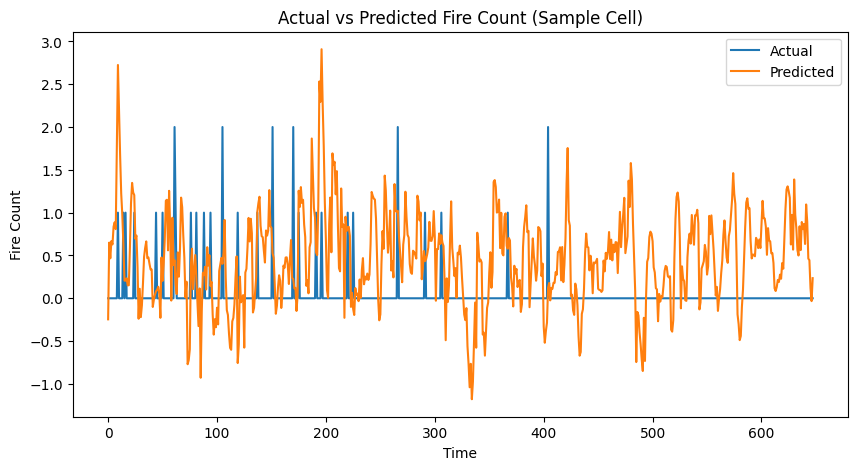

In [17]:
import matplotlib.pyplot as plt

cell_idx = 0  # Pick a cell to visualize
plt.figure(figsize=(10,5))
plt.plot(y_test_inv[:, cell_idx], label='Actual')
plt.plot(y_pred_inv[:, cell_idx], label='Predicted')
plt.xlabel('Time')
plt.ylabel('Fire Count')
plt.title('Actual vs Predicted Fire Count (Sample Cell)')
plt.legend()
plt.show()


5.4. Heatmap of Predicted Fire Spread at a Time Step

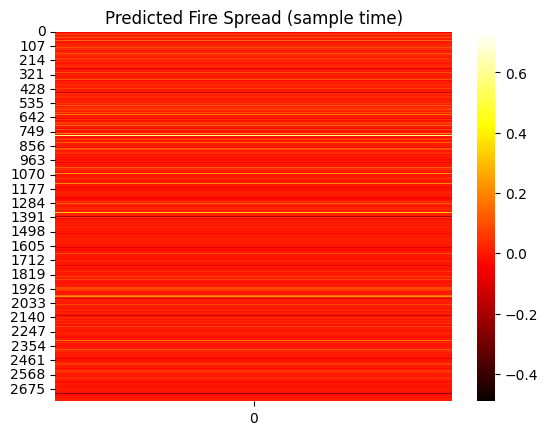

In [18]:
import seaborn as sns

# Pick a time step to visualize
time_idx = 0
predicted_grid = y_pred_inv[time_idx].reshape(pivot.shape[1]//1, 1)
sns.heatmap(predicted_grid, cmap='hot')
plt.title('Predicted Fire Spread (sample time)')
plt.show()


# Geographical Scatter Plot of Fire Detections

In [22]:
df['datetime'] = pd.to_datetime(df['acq_date'] + ' ' + df['acq_time'].astype(str).str.zfill(4), format='%Y-%m-%d %H%M')
fires_per_day = df.groupby(df['datetime'].dt.date).size()

plt.figure(figsize=(12,5))
fires_per_day.plot()
plt.title('Number of Fire Detections per Day')
plt.xlabel('Date')
plt.ylabel('Fire Detections')
plt.grid()
plt.show()


ValueError: time data "acq_date acq_time" doesn't match format "%Y-%m-%d %H%M", at position 0. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.